# Clinical Survival Prediction Using SUPPORT2

## Research objectives

Patients have different variables, demographic and clinical. I want to investigate whether they can predict time-to-death or time-to-event using statistical survival analysis and machine learning.

First, I'll compare Kaplan-Meier survival estimates, Cox proportional hazards regression and finally random survival forest models.

## 1. Datasets: SUPPORT2

SUPPORT is the Study to Understand Prognoses and Preferences for Outcomes and Risks of Treatments. It is a dataset of collected clinical data from 9105 seriously ill hospitalized patients across five US centers.

### Survival endpoints
- **Time:** 'd.time', follow-up duration in days.
- **Event:** 'death', where 1 indicates observed death and 0 indicates right-censoring.

Right-censoring happens when death/event hasn't been observed by the end of a patient's follow-up.

**Source:** UCI Machine Learning Repository, SUPPORT2 (ID 880) 

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from lifelines import KaplanMeierFitter

In [13]:
sns.set_theme(style="whitegrid")

#Fetching SUPPORT2 using its specific id

support2 = fetch_ucirepo(id=880)
df = support2.data.original.copy() #Copy-Pasting it into a new df variable to preserve the original fetch

print(f"Patients: {df.shape[0]}")
print(f"Variables: {df.shape[1]}")


Patients: 9105
Variables: 48


In [14]:
display(df.head())

#UCI supplied variable metadata

display(support2.variables[
    ["name", "role", "type", "description", "missing_values"]
])

# Data types

display(df.info())

# Descriptif or summary statistics

display(df.describe())

,id,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,totmcst,avtisst,race,sps,aps,surv2m,surv6m,hday,diabetes,dementia,ca,prg2m,prg6m,dnr,dnrday,meanbp,wblc,hrt,resp,temp,pafi,alb,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc
0,1,62.84998,0,male,0,5,2029,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,NaN,7.000000,other,33.898438,20.0,0.262939,0.036995,1,0,0,metastatic,0.50,0.25,no dnr,5.0,97.0,6.000000,69.0,22.0,36.00000,388.00000,1.799805,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,NaN,7.0
1,2,60.33899,1,female,1,4,4,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,NaN,29.000000,white,52.695312,74.0,0.001000,0.000000,3,0,0,no,0.00,0.00,NaN,NaN,43.0,17.097656,112.0,34.0,34.59375,98.00000,NaN,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,<2 mo. follow-up,1.0
2,3,52.74698,1,female,0,17,47,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,NaN,13.000000,white,20.500000,45.0,0.790894,0.664917,4,0,0,no,0.75,0.50,no dnr,17.0,70.0,8.500000,88.0,28.0,37.39844,231.65625,NaN,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,<2 mo. follow-up,0.0
3,4,42.38498,1,female,0,3,133,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,NaN,7.000000,white,20.097656,19.0,0.698975,0.411987,1,0,0,metastatic,0.90,0.50,no dnr,3.0,75.0,9.099609,88.0,32.0,35.00000,NaN,NaN,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,no(M2 and SIP pres),0.0
4,5,79.88495,0,female,0,16,2029,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,NaN,18.666656,white,23.500000,30.0,0.634888,0.532959,3,0,0,no,0.90,0.90,no dnr,16.0,59.0,13.500000,112.0,20.0,37.89844,173.31250,NaN,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,no(M2 and SIP pres),2.0


,name,role,type,description,missing_values
0,id,ID,Integer,None,no
1,age,Feature,Continuous,Age of the patients in years,no
2,death,Target,Continuous,Death at any time up to National Death Index (...,no
3,sex,Feature,Categorical,Gender of the patient. Listed values are {male...,no
4,hospdead,Target,Binary,Death in hospital,no
5,slos,Other,Continuous,Days from Study Entry to Discharge,no
6,d.time,Other,Continuous,Days of follow-up,no
7,dzgroup,Feature,Categorical,The patient's disease sub category amogst ARF/...,no
8,dzclass,Feature,Categorical,"The patient's disease category amongst ""ARF/MO...",no
9,num.co,Feature,Continuous,The number of simultaneous diseases (or comorb...,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9105 entries, 0 to 9104
Data columns (total 48 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        9105 non-null   int64  
 1   age       9105 non-null   float64
 2   death     9105 non-null   int64  
 3   sex       9105 non-null   object 
 4   hospdead  9105 non-null   int64  
 5   slos      9105 non-null   int64  
 6   d.time    9105 non-null   int64  
 7   dzgroup   9105 non-null   object 
 8   dzclass   9105 non-null   object 
 9   num.co    9105 non-null   int64  
 10  edu       7471 non-null   float64
 11  income    6123 non-null   object 
 12  scoma     9104 non-null   float64
 13  charges   8933 non-null   float64
 14  totcst    8217 non-null   float64
 15  totmcst   5630 non-null   float64
 16  avtisst   9023 non-null   float64
 17  race      9063 non-null   object 
 18  sps       9104 non-null   float64
 19  aps       9104 non-null   float64
 20  surv2m    9104 non-null   floa

None

,id,age,death,hospdead,slos,d.time,num.co,edu,scoma,charges,totcst,totmcst,avtisst,sps,aps,surv2m,surv6m,hday,diabetes,dementia,prg2m,prg6m,dnrday,meanbp,wblc,hrt,resp,temp,pafi,alb,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc
count,9105.000000,9105.000000,9105.000000,9105.000000,9105.000000,9105.000000,9105.000000,7471.000000,9104.000000,8.933000e+03,8217.000000,5630.000000,9023.000000,9104.000000,9104.000000,9104.000000,9104.000000,9105.000000,9105.000000,9105.000000,7456.000000,7472.000000,9075.000000,9104.000000,8893.000000,9104.000000,9104.000000,9104.000000,6780.000000,5733.000000,6504.000000,9038.000000,9104.000000,6821.000000,4605.000000,4753.000000,4243.000000,3464.000000,6238.000000,9105.000000
mean,4553.000000,62.650823,0.681054,0.259198,17.863042,478.449863,1.868644,11.747691,12.058546,5.999579e+04,30825.867768,28828.877838,22.610928,25.525872,37.597979,0.635870,0.520096,4.400000,0.195277,0.032510,0.618769,0.499679,14.582590,84.546408,12.347677,97.156711,23.330294,37.103341,239.529070,2.950520,2.554463,1.770961,137.568541,7.415364,159.873398,32.349463,2191.546047,1.157910,1.637384,1.888272
std,2628.531434,15.593710,0.466094,0.438219,22.006440,560.383272,1.344409,3.447743,24.636694,1.026488e+05,45780.820986,43604.261932,13.233248,9.899377,19.903852,0.248175,0.253343,9.126811,0.396436,0.177359,0.298367,0.304367,19.944216,27.687692,9.266329,31.559292,9.573801,1.251796,109.665593,0.875944,5.318448,1.686041,6.029326,0.080563,88.391541,26.792288,1455.245777,1.739672,2.231358,2.003763
min,1.000000,18.041990,0.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,1.169000e+03,0.000000,-102.719970,1.000000,0.199982,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,-88.000000,0.000000,0.000000,0.000000,0.000000,31.699220,12.000000,0.399963,0.099991,0.099991,110.000000,6.829102,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2277.000000,52.797000,0.000000,0.000000,6.000000,26.000000,1.000000,10.000000,0.000000,9.740000e+03,5929.566400,5177.404300,12.000000,19.000000,23.000000,0.507690,0.342957,1.000000,0.000000,0.000000,0.500000,0.200000,4.000000,63.000000,7.000000,72.000000,18.000000,36.195310,155.093750,2.399902,0.500000,0.899902,134.000000,7.379883,103.000000,14.000000,1165.500000,0.000000,0.000000,0.000000
50%,4553.000000,64.856990,1.000000,0.000000,11.000000,233.000000,2.000000,12.000000,0.000000,2.502400e+04,14452.734400,13223.500000,19.500000,23.898438,34.000000,0.715942,0.574951,1.000000,0.000000,0.000000,0.700000,0.500000,9.000000,77.000000,10.599609,100.000000,24.000000,36.695310,224.000000,2.899902,0.899902,1.199951,137.000000,7.419922,135.000000,23.000000,1968.000000,0.000000,1.000000,1.000000
75%,6829.000000,73.998960,1.000000,1.000000,20.000000,761.000000,3.000000,14.000000,9.000000,6.459800e+04,36087.937500,34223.601600,31.666656,30.199219,49.000000,0.825928,0.725952,3.000000,0.000000,0.000000,0.900000,0.750000,17.000000,107.000000,15.298828,120.000000,28.000000,38.195310,304.750000,3.599609,1.899902,1.899902,141.000000,7.469727,188.000000,42.000000,3000.000000,2.000000,3.000000,3.000000
max,9105.000000,101.847960,1.000000,1.000000,343.000000,2029.000000,9.000000,31.000000,100.000000,1.435423e+06,633212.000000,710682.000000,83.000000,99.187500,143.000000,0.969971,0.947998,148.000000,1.000000,1.000000,1.000000,1.000000,285.000000,195.000000,200.000000,300.000000,90.000000,41.695310,890.375000,29.000000,63.000000,21.500000,181.000000,7.769531,1092.000000,300.000000,9000.000000,7.000000,7.000000,7.073242


The original SUPPORT documentation advises excluding **aps, sps, surv2m and surv6m** when developing independent models. Also, it suggests avoiding physician predictions and DNR-related variables.    

## 2. Data quality and missingness

Clinical datasets commonly contain missing observations due to
incomplete medical records, unavailable laboratory measurements,
or differences in data collection.

I'll examine:
1. Missing values across variables.
2. The distribution of follow-up time.
3. The proportion of observed deaths and censored patients.

Imputation will be performed later, using training data only,
to prevent data leakage into validation and test sets.

In [15]:
missing  = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing = missing.sort_values(
    "missing_pct",ascending = False
)

display(missing.head(20).round(2))

,missing_count,missing_pct
adlp,5641,61.95
urine,4862,53.40
glucose,4500,49.42
bun,4352,47.80
totmcst,3475,38.17
alb,3372,37.03
income,2982,32.75
adls,2867,31.49
bili,2601,28.57
pafi,2325,25.54


Here we see very high missingness. Three possible strategies :

- Drop the variable: Simple, but potentially loses valuable clinical information.

- Impute missing values: For instance, replace missing numerical observations with the median calculated from the training set.

- Add a missingness indicator: A binary variable identifying whether a measurement was originally missing. This can be useful because missing clinical measurements may reflect how patients were assessed.


For now, It's better to keep it as it is.

## 3. Survival Outcome Exploration

Before preprocessing the data furthermore, I'll examine the survival outcomes to better understand the study population.

In SUPPORT2, survival is described by two variables:

- **`death`**: Event indicator (1 = observed death, 0 = right-censored).
- **`d.time`**: Follow-up duration in days.

Because several physiological measurements were collected on study day 3 specifically, patients whose follow-up ended before or on that day may not be suitable for a predictive model using those measurements.

Therefore I'll examine the distribution of events, follow-up durations, and the number of patients who died or were censored within the first three days.

This preliminary analysis will help determine the eligible population for a **day-3 landmark survival analysis**, while retaining the original cohort for descriptive purposes.

In [16]:
display(df["death"].value_counts()) # Deaths versus censored observations

display(df["d.time"].describe()) #Follow-up duration

day3 = df[df["d.time"] > 3].copy() # Patients observed beyond study day 3

early =df[df["d.time"] <= 3].copy() # Patients whose follow-up ended by day 3 

day3["time"] = day3["d.time"] - 3 # Survival time measured from day 3

day3["event"] = day3["death"] # Event here is death

print("Early deaths:", ((df["death"] == 1) & (df["d.time"] <= 3)).sum())
print("Early censoring:", ((df["death"] == 0) & (df["d.time"] <= 3)).sum())

df.to_csv("support2.csv", index=False) # I'll use this for the R version of this clinical data analysis

death
1    6201
0    2904
Name: count, dtype: int64

count    9105.000000
mean      478.449863
std       560.383272
min         3.000000
25%        26.000000
50%       233.000000
75%       761.000000
max      2029.000000
Name: d.time, dtype: float64

Early deaths: 138
Early censoring: 0


In [17]:
exclude = [
    "id",
    "death", "d.time",
    "hospdead", "slos", "sfdm2",
    "aps", "sps", "surv2m", "surv6m",
    "prg2m", "prg6m",
    "dnr", "dnrday",
    "charges", "totcst", "totmcst", "avtisst"
]

X = df.drop(columns=exclude) #Input features (Patient characterisitics), these are predictors.

display(X.columns)

X = X.loc[day3.index].copy() # Keep only rows corresponding to patients elligible for the day-3 analysis

display((X.isna().mean()*100).sort_values(ascending=False).to_frame("Missing (%)").round(2))

Index(['age', 'sex', 'dzgroup', 'dzclass', 'num.co', 'edu', 'income', 'scoma',
       'race', 'hday', 'diabetes', 'dementia', 'ca', 'meanbp', 'wblc', 'hrt',
       'resp', 'temp', 'pafi', 'alb', 'bili', 'crea', 'sod', 'ph', 'glucose',
       'bun', 'urine', 'adlp', 'adls', 'adlsc'],
      dtype='object')

,Missing (%)
adlp,61.39
urine,53.37
glucose,49.40
bun,47.76
alb,37.04
income,32.49
adls,30.87
bili,28.49
pafi,25.74
ph,25.28


In [18]:
from sklearn.model_selection import train_test_split


y = day3.loc[X.index, ["time", "event"]] # Outcomes as labels in this supervised learning


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y["event"]
)  # 80% of the dataset is for training and 20% for testing. Stratify preserves the same approximate proportions of observed deaths and censored patients in both sets. 

print(X_train.shape, X_test.shape)

(7173, 30) (1794, 30)


30 input features each, 7173 patients for training and the rest for testing.

Now, we need to seperate numerical from categorical features.

In [19]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

print("Numerical:", num_cols.tolist())
print("Categorical:", cat_cols.tolist())
print(X_train["diabetes"].unique())
print(X_train["dementia"].unique())

Numerical: ['age', 'num.co', 'edu', 'scoma', 'hday', 'diabetes', 'dementia', 'meanbp', 'wblc', 'hrt', 'resp', 'temp', 'pafi', 'alb', 'bili', 'crea', 'sod', 'ph', 'glucose', 'bun', 'urine', 'adlp', 'adls', 'adlsc']
Categorical: ['sex', 'dzgroup', 'dzclass', 'income', 'race', 'ca']
[0 1]
[0 1]


In [20]:
for col in ["adlp", "edu", "diabetes", "dementia"]:
    print(f"{col}: {X_train[col].dropna().unique()}")

adlp: [3. 4. 6. 0. 1. 2. 5. 7.]
edu: [ 5.  8. 11. 12. 16. 14. 19. 18.  9.  6. 15. 20. 13.  7. 10. 17.  4.  3.
  1.  0. 22. 21. 24.  2. 23. 27. 26. 31. 28. 30. 25.]
diabetes: [0 1]
dementia: [0 1]


adlp has an ordered clinical score, edu are years of education. Diabetes and dementia are binary variables.

## 4. Missing Data Preprocessing

To fix the missigness issue, I'll do imputation.

Numerical missing values are imputed using the median, whereas categorical
missing values are imputed using the most frequent category.

Also, Missingness indicators are added for numerical variables.

Most importantly, reprocessing is fitted exclusively on training data to prevent
information leakage into the test set.

In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Here I'm going to define the preprocessing program

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

## 5. Kaplan–Meier Survival Analysis

The Kaplan–Meier estimator provides a nonparametric estimate
of survival probability over time, accounting for right-censoring.

I estimate overall survival in the day-3 eligible cohort.
This provides a descriptive baseline for subsequent prediction models.

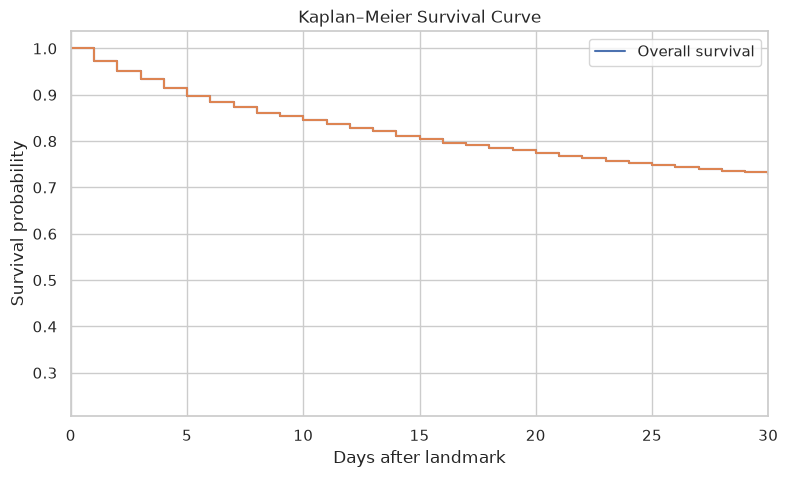

In [28]:
from lifelines import KaplanMeierFitter

km = KaplanMeierFitter()

km.fit(
    durations=day3["time"],
    event_observed=day3["event"],
    label="Overall survival"
)

fig, ax = plt.subplots(figsize=(9, 5))
km.plot_survival_function(ax=ax, ci_show=False)

plt.step(
    km.survival_function_.index,
    km.survival_function_.iloc[:, 0],
    where="post"
)

plt.xlim(0, 30)
plt.xlabel("Days after landmark")
plt.ylabel("Survival probability")
plt.title("Kaplan–Meier Survival Curve")
plt.show()


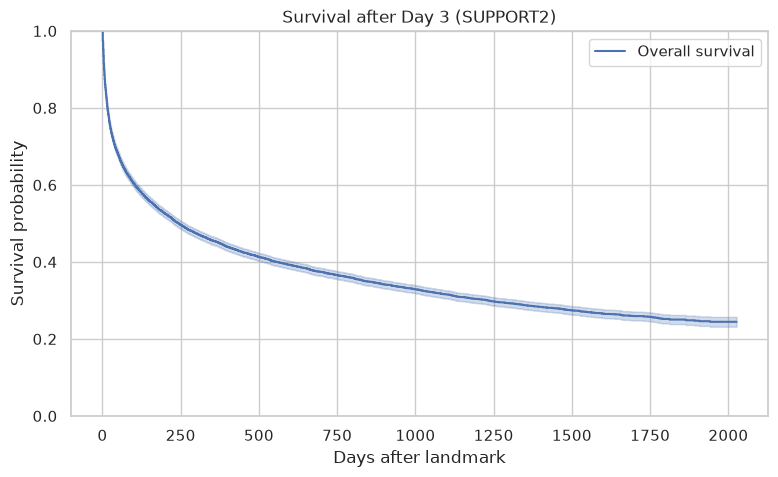

Day 30: 72.95%
Day 180: 53.69%
Day 365: 45.24%


In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
km.plot_survival_function(ax=ax)

ax.set(
    title="Survival after Day 3 (SUPPORT2)",
    xlabel="Days after landmark",
    ylabel="Survival probability",
    ylim=(0, 1)
)

plt.show()

for t in [30, 180, 365]:
    print(f"Day {t}: {km.predict(t):.2%}")

### Interpretation of Kaplan-Meier survival estimates

We see a progressive decline in survival probability among selected patients, the decline was substantial during the first year reflecting the severity of illness in tthe SUPPORT2 population. 

However, the estimated survival probability remains above 20% even around day 2,000, suggesting that a subset of patients experiences considerably longer survival.

Nevertheless, estimates near the end of follow-up may be less reliable because fewer patients remain at risk. We should examine confidence intervals with the numbers of patients at risk brfore interpreting long-term survival.

Overall, these findings highlight substantial mortality risk and variability in patients survival. Thus encouraging individualized prognostic models.

## 6. Survival Prediction Models

I'll compare two approaches:

- Cox proportional hazards regression: a statistical model
  describing relationships between clinical predictors and mortality risk.
- Random Survival Forest: a nonlinear ensemble model capable
  of capturing complex relationships and interactions.

Both models use the same dataset and preprocessing procedures in order to ensure a fair comparaison based on their predictif abilities.

Regularization is applied to Cox regression to reduce overfitting and for numerical stability as some predictors like dzgroup and dzclass may be strongly correlated.

In [ ]:
from sklearn.base import clone
from sksurv.util import Surv
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.ensemble import RandomSurvivalForest

# Convert targets to structured survival arrays

ys_train = Surv.from_arrays(
    y_train["event"].astype(bool),
    y_train["time"].astype(float)
)

ys_test = Surv.from_arrays(
    y_test["event"].astype(bool),
    y_test["time"].astype(float)
)

models = {
    "Cox": CoxPHSurvivalAnalysis(alpha=10.0), #alpha controls L2 regularization, the higher the stronger the penality is on large model coeficcients, reducing overfitting.
    "RSF": RandomSurvivalForest(
        n_estimators=100, #Number of survival trees in the forest,100 trees to combine their predictions.
        min_samples_leaf=10,# Minimum number of patients allowed in each terminal leaf. This prevents predictions based on very small patient groups
        min_samples_split=20, # Minimum number of patients a node must contain before attempting a split. It limits excessive tree growth
        random_state=42,  
        n_jobs=-1 #Use all available CPU cores
    )
}

for name, estimator in models.items():
    models[name] = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", estimator)
    ])

    models[name].fit(X_train, ys_train)
    print(f"{name} : trained")



Cox : trained
RSF : trained


## 7. Model Evaluation

The models are evaluated on the held-out test set using:

- Concordance index (C-index). It measures how accurately the
  model ranks patients by mortality risk. Higher is better.
  
- Brier score. It measures survival probability prediction error,
  accounting for censoring. Lower is better.

Also, prediction errors are evaluated at 180 and 365 days
after the landmark.

This is an initial comparison without hyperparameter optimization.

In [31]:
from sksurv.metrics import concordance_index_censored, brier_score

def truncate_survival(y, horizon=365):
    result = y.copy()
    result["event"] &= result["time"] <= horizon
    result["time"] = np.minimum(result["time"], horizon + 1)
    return result

eval_train = truncate_survival(ys_train)
eval_test = truncate_survival(ys_test)

times = np.array([180, 365])
results = []

for name, model in models.items():
    risk = model.predict(X_test)

    c_index = concordance_index_censored(
        ys_test["event"],
        ys_test["time"],
        risk
    )[0]

    curves = model.predict_survival_function(X_test)

    probabilities = np.array([
        [fn(t) for t in times]
        for fn in curves
    ])

    _, brier = brier_score(
        eval_train,
        eval_test,
        probabilities,
        times
    )

    results.append({
        "Model": name,
        "C-index": c_index,
        "Brier 180d": brier[0],
        "Brier 365d": brier[1]
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,C-index,Brier 180d,Brier 365d
0,Cox,0.6907,0.2013,0.1986
1,RSF,0.6827,0.1975,0.1976


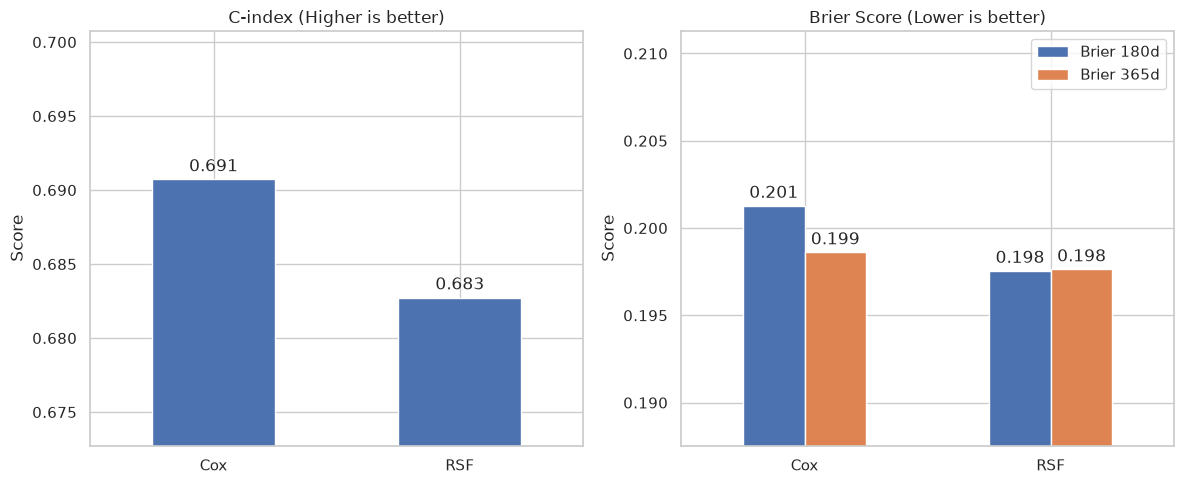

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

results_df.plot.bar(
    x="Model", y="C-index",
    ax=axes[0], legend=False,
    title="C-index (Higher is better)"
)

results_df.plot.bar(
    x="Model", y=["Brier 180d", "Brier 365d"],
    ax=axes[1],
    title="Brier Score (Lower is better)"
)


for ax, cols in zip(
    axes,
    [["C-index"], ["Brier 180d", "Brier 365d"]]
):
    values = results_df[cols].to_numpy().ravel()
    margin = max((values.max() - values.min()) * 0.25, 0.01)

    ax.set_ylim(
        max(0, values.min() - margin),
        min(1, values.max() + margin)
    )

    
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", padding=3)

    ax.tick_params(axis="x", rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

As we see, **Cox proportional hazards** achieved slightly better discrimination (C-index = 0.691), thus indicating a greater ability to correctly rank patients according to mortality risk compared to RSF.

Then, **Random Survival Forest** achieved marginally lower Brier scores at both prediction horizons which suggests slightly better survival probability predictions.

Overall, both models showed moderate discriminatory performance, with relatively small differences between them. Nevertheless, the additional complexity of RSF did not produce a clear improvement over Cox regression.

At this stage, uncertainty in these differences has not yet been assessed. It'll be examined in the bootstrap analysis below.

The study is limitted, there's a need for **more validation and calibration**.

## 10. Cox Proportional Hazards Diagnostics

The assumptions weren't assessed before as should, here I start it over. 

**I kept the previous results to showcase how more validation could change the performances.**

The proportional hazards assumption is assessed the best here using
Schoenfeld residuals.

A significant association between residuals and survival time
may indicate that a predictor's hazard ratio changes over time and not merely randomly.
Diagnostics are performed exclusively on the training cohort to prevent test-set information from influencing model development, thereby avoiding data leakage during this stage.

In [ ]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test


cox_prep = models["Cox"].named_steps["preprocessing"] # Preprocessing already fitted for Cox

X_processed = cox_prep.transform(X_train)
feature_names = cox_prep.get_feature_names_out()

cox_data = pd.DataFrame(
    X_processed,
    columns=feature_names,
    index=X_train.index
)

cox_data["time"] = y_train["time"]
cox_data["event"] = y_train["event"]


cph = CoxPHFitter(penalizer=0.1) # Refit an equivalent Cox specification for diagnostics

cph.fit(
    cox_data,
    duration_col="time",
    event_col="event"
)

ph_test = proportional_hazard_test(
    cph,
    cox_data,
    time_transform="rank"
)

ph_results = ph_test.summary.sort_values("p")

display(ph_results.head(15))
print("Variables with p < 0.05:",
      (ph_results["p"] < 0.05).sum())

,test_statistic,p,-log2(p)
num__scoma,79.983742,3.775032e-19,61.200145
num__missingindicator_adlp,65.701863,5.245625e-16,50.759735
num__bili,17.458461,2.936543e-05,15.055521
num__hrt,8.309743,3.943298e-03,7.986382
cat__dzgroup_COPD,8.301465,3.961311e-03,7.979806
num__pafi,8.070452,4.499290e-03,7.796087
cat__dzgroup_CHF,6.896522,8.636361e-03,6.855361
cat__dzgroup_Colon Cancer,6.769117,9.274870e-03,6.752457
num__meanbp,6.255133,1.238340e-02,6.335449
cat__dzclass_COPD/CHF/Cirrhosis,6.038077,1.400052e-02,6.158375


Variables with p < 0.05: 17


A small p-value (< 0.05, the alpha here) suggests possible non-proportional hazards. Because we're testing many predictors, some significant results may occur by chance. We should inspect the largest violations before considering changes to the model.

## 11. Cross-Validation

The initial C-index results were based on a single train-test split, a cross-validation would show if the performances are stable or not.

A five-fold stratified cross-validation is performed on the training
cohort to evaluate model robustness.

All preprocessing steps are refitted within each training fold
to prevent data leakage.

Finally, The held-out test cohort remains excluded from cross-validation.

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(X_train, ys_train["event"]))

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        ys_train,
        cv=folds,
        scoring=None,
        n_jobs=1
    )

    cv_results[name] = scores

    print(f"{name}")
    print(f"  Fold scores: {np.round(scores, 3)}")
    print(f"  Mean C-index: {scores.mean():.3f}")
    print(f"  SD: {scores.std(ddof=1):.3f}\n")

Cox
  Fold scores: [0.693 0.702 0.691 0.68  0.678]
  Mean C-index: 0.689
  SD: 0.010

RSF
  Fold scores: [0.69  0.694 0.69  0.685 0.677]
  Mean C-index: 0.687
  SD: 0.007



- **Cox:** Mean C-index = 0.689 ± 0.010 (SD)
- **RSF:** Mean C-index = 0.687 ± 0.007 (SD)

Both models demonstrated relatively stable discrimination across
training folds, with Cox achieving a marginally higher mean C-index.

Cross-validation assesses both predictive performance and its stability across folds. Yet, the small difference in mean C-index does not establish a clear advantage for either model.

## 12. Bootstrap Confidence Intervals

Paired bootstrap resampling (500 iterations) is used to estimate
95% confidence intervals for the test-set C-index. Also, the difference between model C-indices is also examined to
assess uncertainty in their relative performance.

In [38]:
from sksurv.metrics import concordance_index_censored

rng = np.random.default_rng(42)

risks = {
    name: model.predict(X_test)
    for name, model in models.items()
}

boot = []

for _ in range(500):
    idx = rng.choice(len(ys_test), len(ys_test), replace=True)

    event = ys_test["event"][idx]
    time = ys_test["time"][idx]

    if event.sum() < 2:
        continue

    scores = {
        name: concordance_index_censored(
            event, time, risk[idx]
        )[0]
        for name, risk in risks.items()
    }

    scores["Difference (Cox - RSF)"] = (
        scores["Cox"] - scores["RSF"]
    )

    boot.append(scores)

boot_df = pd.DataFrame(boot)

ci = pd.DataFrame({
    "Estimate": [
        results_df.set_index("Model").loc["Cox", "C-index"],
        results_df.set_index("Model").loc["RSF", "C-index"],
        results_df.set_index("Model").loc["Cox", "C-index"] -
        results_df.set_index("Model").loc["RSF", "C-index"]
    ],
    "CI lower": boot_df.quantile(0.025),
    "CI upper": boot_df.quantile(0.975)
}, index=["Cox", "RSF", "Difference (Cox - RSF)"])

display(ci.round(4))

,Estimate,CI lower,CI upper
Cox,0.6907,0.6738,0.7047
RSF,0.6827,0.6670,0.6958
Difference (Cox - RSF),0.0080,0.0005,0.0157


Considering the results, the confidence interval for the difference excludes zero, thus suggesting a small statistical advantage for Cox regression in discriminating mortality risk.

However, the lower bound is very close to zero, and the magnitude of the difference is unlikely to establish clinical superiority on its own.

## 13. Survival Probability Calibration

Calibration assesses agreement between predicted and observed
survival probabilities. So, patients are divided into five groups according to their
predicted one-year survival probability.

Within each group, observed survival is estimated using the
Kaplan–Meier method to account for right-censoring.

Finally, Perfect calibration corresponds to the diagonal reference line.

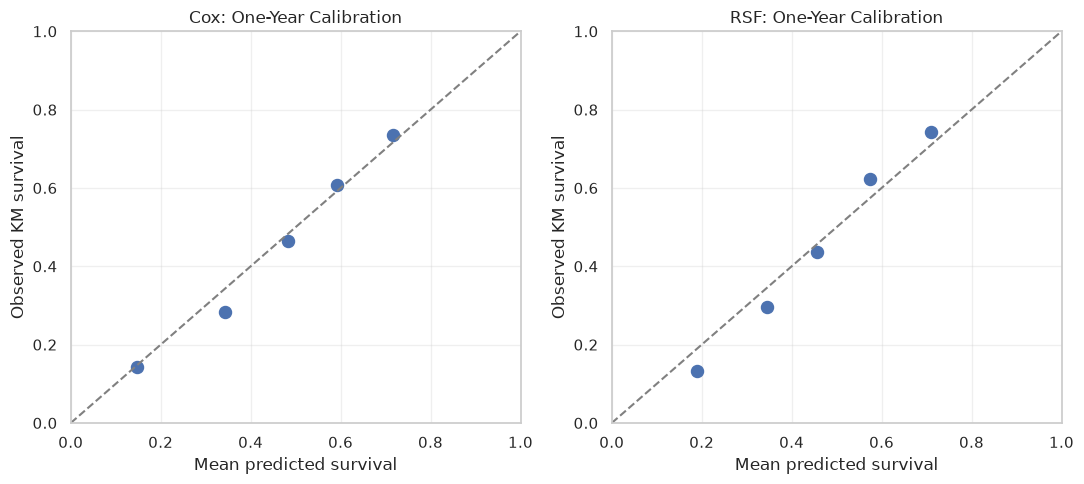

In [ ]:
HORIZON = 365

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, (name, model) in zip(axes, models.items()):

    curves = model.predict_survival_function(X_test)

    predicted = np.array([
        fn(HORIZON) for fn in curves
    ])

    calibration = pd.DataFrame({
        "predicted": predicted,
        "time": y_test["time"].to_numpy(),
        "event": y_test["event"].to_numpy()
    })

    calibration["group"] = pd.qcut(
        calibration["predicted"],
        q=5,
        labels=False,
        duplicates="drop"
    )

    observed = []
    expected = []

    for _, group in calibration.groupby("group"):
        kmf = KaplanMeierFitter()
        kmf.fit(group["time"], group["event"])

        observed.append(kmf.predict(HORIZON))
        expected.append(group["predicted"].mean())

    ax.scatter(expected, observed, s=75)
    ax.plot([0, 1], [0, 1], "--", color="gray")

    ax.set(
        title=f"{name} (One-Year Calibration)",
        xlabel="Mean predicted survival",
        ylabel="Observed KM survival",
        xlim=(0, 1),
        ylim=(0, 1)
    )

    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Both models demonstrate reasonably good agreement between predicted and observed one-year survival probabilities. However, they overestimate survival in some groups with lower predicted survival probabilities. Nevertheless,they gave a promising preliminary calibration.

## 14. Clinical Subgroup Analysis

Previously, the analysis was quite general. It would be better to investigate per clinical group.   

Predictive discrimination is evaluated separately across patient
sex and primary diagnostic categories. Subgroup C-indices help identify whether model performance
varies across clinically distinct populations.

Also, the results are exploratory and may be less precise in smaller
subgroups. Thus, they are not interpreted as evidence of causality
or clinical fairness.

In [40]:
subgroup_results = []

for variable in ["sex", "dzclass"]:

    for group in X_test[variable].dropna().unique():

        mask = X_test[variable].eq(group).to_numpy()

        n = mask.sum()
        events = ys_test["event"][mask]
        times = ys_test["time"][mask]

        if n < 80 or events.sum() < 20:
            continue

        for name, risk in risks.items():

            score = concordance_index_censored(
                events, times, risk[mask]
            )[0]

            subgroup_results.append({
                "Variable": variable,
                "Group": group,
                "Model": name,
                "Patients": n,
                "Deaths": events.sum(),
                "C-index": score
            })

subgroup_df = pd.DataFrame(subgroup_results)

display(
    subgroup_df.sort_values(
        ["Variable", "Group", "Model"]
    ).round(3)
)

,Variable,Group,Model,Patients,Deaths,C-index
4,dzclass,ARF/MOSF,Cox,827,523,0.686
5,dzclass,ARF/MOSF,RSF,827,523,0.683
8,dzclass,COPD/CHF/Cirrhosis,Cox,562,337,0.631
9,dzclass,COPD/CHF/Cirrhosis,RSF,562,337,0.633
10,dzclass,Cancer,Cox,289,251,0.633
11,dzclass,Cancer,RSF,289,251,0.666
6,dzclass,Coma,Cox,116,102,0.658
7,dzclass,Coma,RSF,116,102,0.679
2,sex,female,Cox,817,539,0.690
3,sex,female,RSF,817,539,0.682


Subgroup analysis revealed differences in predictive discrimination across diagnostic categories, performance remained relatively consistent between male and female patients, although.Thus, the results suggest that model performance may depend on the underlying clinical population. Cox remained competitive and stable overall, while RSF showed greater discrimination in the cancer and coma subgroups.

However, subgroup differences were not assessed with confidence intervals or statistical tests. Additionnally, differences in sample size, patient characteristics, and censoring patterns may also influence the observed C-indices.

Finally, these findings are exploratory and do not establish that either model is clinically superior for a particular disease.

## 15. Predictor Availability and Leakage Audit

Predictor definitions are reviewed to identify variables that
may contain derived estimates, previous imputations, or
information unavailable at the day-3 prediction landmark.

This audit complements and doesn't replace statistical validation because
high predictive performance alone cannot exclude data leakage.

In [41]:
audit = (
    support2.variables
    .set_index("name")
    .reindex(X_train.columns)[["description"]]
    .copy()
)

audit["Review required"] = (
    audit["description"]
    .fillna("")
    .str.contains(
        "predicted|imputed|after|days 3-25",
        case=False,
        regex=True
    )
)

display(audit[audit["Review required"]])

,description,Review required
scoma,SUPPORT day 3 Coma Score based on Glasgow scal...,True
adlsc,Imputed ADL Calibrated to Surrogate.,True


Neither variable necessarily represents temporal leakage, but excluding them makes our preprocessing more transparent and independent.

In [42]:
remove = ["scoma", "adlsc"]

X_train_reduced = X_train.drop(columns=remove)
X_test_reduced = X_test.drop(columns=remove)

print("Remaining features:", X_train_reduced.shape[1])

Remaining features: 28


## 16. Feature Exclusion Sensitivity Analysis

Two previously derived variables (`scoma` and `adlsc`) were
excluded to assess their influence on predictive performance. The comparison evaluates whether these exclusions materially
affect predictive discrimination.

In [43]:

reduced_preprocessor = ColumnTransformer([
    ("num", clone(num_pipeline),
     [c for c in num_cols if c not in remove]),
    ("cat", clone(cat_pipeline), list(cat_cols))
])

reduced_models = {}
comparison = []

for name, original_model in models.items():

    reduced_model = Pipeline([
        ("preprocessing", clone(reduced_preprocessor)),
        ("model", clone(original_model.named_steps["model"]))
    ])

    reduced_model.fit(X_train_reduced, ys_train)
    reduced_models[name] = reduced_model

    comparison.append({
        "Model": name,
        "Original (30)": original_model.score(X_test, ys_test),
        "Reduced (28)": reduced_model.score(X_test_reduced, ys_test)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df["Difference"] = (
    comparison_df["Reduced (28)"] -
    comparison_df["Original (30)"]
)

display(comparison_df.round(4))

,Model,Original (30),Reduced (28),Difference
0,Cox,0.6907,0.6802,-0.0106
1,RSF,0.6827,0.6736,-0.0091


Removing scoma and adlsc slightly reduced discrimination for both models, thus suggesting that these variables contributed useful predictive information, although neither was essential to model performance.

### Comparison with Published Research

These models achieved moderate discrimination, with C-indices of 0.691 for Cox regression and 0.683 for Random Survival Forest.

Higher C-indices have been reported in other SUPPORT2 analyses and benchmarks. However, differences in patient selection, predictor availability, preprocessing and evaluation protocols limit direct comparability.

These models were not systematically optimized, leaving potential room for improved predictive performance.

Future work should investigate hyperparameter optimization and reproduce published benchmarking protocols to determine whether the performance gap arises from model configuration or methodological differences.